In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad


plt.rcParams['font.family'] = 'serif'
plt.style.use("seaborn-v0_8-deep")
import os
# Create Plots folder if it doesn't exist
os.makedirs('report/Plots', exist_ok=True)

green = "#70B761"
red = "#C85656"
rng = np.random.default_rng()
grey = '#7f7f7f'
blue = "#2e7bb1"
black = "#363535"

In [4]:

S0 = 30.0
K = 30.0
r = 0.04
sigma = 0.15
T = 1.0

# Strike of the vanilla call used for gamma hedging
K_hedge = 30.0

n_steps = 252
seed = 42


# =============================================================================
# 2. BLACK-SCHOLES HELPER FUNCTIONS
# =============================================================================

def d1(S, K, r, sigma, tau):
    """Black-Scholes d1."""
    return (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * tau
    ) / (sigma * np.sqrt(tau))


def call_price(S, K, r, sigma, tau):
    """Price of the vanilla call used as hedging instrument."""
    if tau <= 0:
        return max(S - K, 0.0)

    d_1 = d1(S, K, r, sigma, tau)
    d_2 = d_1 - sigma * np.sqrt(tau)

    return (
        S * norm.cdf(d_1)
        - K * np.exp(-r * tau) * norm.cdf(d_2)
    )


def call_delta(S, K, r, sigma, tau):
    """Delta of the vanilla call."""
    if tau <= 0:
        return float(S > K)

    return norm.cdf(d1(S, K, r, sigma, tau))


def call_gamma(S, K, r, sigma, tau):
    """Gamma of the vanilla call."""
    if tau <= 0:
        return 0.0

    return (
        norm.pdf(d1(S, K, r, sigma, tau))
        / (S * sigma * np.sqrt(tau))
    )


# =============================================================================
# 3. TARGET PRODUCT: QUADRATIC PAYOFF
# =============================================================================

def quadratic_payoff(S, K):
    """Terminal payoff (S_T-K)^2."""
    return (S - K)**2


def quadratic_price(S, K, r, sigma, tau):
    """Analytical price of the quadratic payoff."""
    if tau <= 0:
        return quadratic_payoff(S, K)

    return (
        S**2 * np.exp((r + sigma**2) * tau)
        - 2 * K * S
        + K**2 * np.exp(-r * tau)
    )


def quadratic_delta(S, K, r, sigma, tau):
    """Delta of the quadratic product."""
    if tau <= 0:
        return 2 * (S - K)

    return 2 * S * np.exp((r + sigma**2) * tau) - 2 * K


def quadratic_gamma(S, K, r, sigma, tau):
    """Gamma of the quadratic product."""
    if tau <= 0:
        return 2.0

    return 2 * np.exp((r + sigma**2) * tau)


# =============================================================================
# 4. SIMULATE ONE GBM STOCK PATH
# =============================================================================

def simulate_gbm_path(S0, r, sigma, T, n_steps, seed=42):
    """Exact simulation of one risk-neutral GBM path."""
    rng = np.random.default_rng(seed)

    dt = T / n_steps
    times = np.linspace(0, T, n_steps + 1)
    S = np.empty(n_steps + 1)
    S[0] = S0

    for i in range(n_steps):
        Z = rng.standard_normal()

        S[i + 1] = S[i] * np.exp(
            (r - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * Z
        )

    return times, S


# =============================================================================
# 5. DELTA-GAMMA HEDGE WITH THREE ASSETS
# =============================================================================

def delta_gamma_hedge(
    times,
    stock_path,
    K,
    K_hedge,
    r,
    sigma,
    T,
):
    """
    Hedge the quadratic product using:

        1. stock,
        2. cash account,
        3. vanilla call.

    No transaction costs are included in this first test.
    """

    n_steps = len(times) - 1

    portfolio_values = np.zeros(n_steps + 1)
    product_values = np.zeros(n_steps + 1)

    stock_units_path = np.zeros(n_steps + 1)
    call_units_path = np.zeros(n_steps + 1)
    cash_path = np.zeros(n_steps + 1)

    # -------------------------------------------------------------------------
    # Initial hedge
    # -------------------------------------------------------------------------

    S = stock_path[0]
    tau = T

    product_value = quadratic_price(S, K, r, sigma, tau)
    product_delta = quadratic_delta(S, K, r, sigma, tau)
    product_gamma = quadratic_gamma(S, K, r, sigma, tau)

    hedge_call_value = call_price(S, K_hedge, r, sigma, tau)
    hedge_call_delta = call_delta(S, K_hedge, r, sigma, tau)
    hedge_call_gamma = call_gamma(S, K_hedge, r, sigma, tau)

    # Number of vanilla calls needed to match gamma
    call_units = product_gamma / hedge_call_gamma

    # Number of shares needed after accounting for the call delta
    stock_units = product_delta - call_units * hedge_call_delta

    # Cash makes the total hedge value equal to the product value
    cash = (
        product_value
        - stock_units * S
        - call_units * hedge_call_value
    )

    product_values[0] = product_value
    portfolio_values[0] = product_value
    stock_units_path[0] = stock_units
    call_units_path[0] = call_units
    cash_path[0] = cash

    # -------------------------------------------------------------------------
    # Dynamic rebalancing
    # -------------------------------------------------------------------------

    for i in range(1, n_steps + 1):

        dt = times[i] - times[i - 1]

        # Cash account earns the risk-free rate
        cash *= np.exp(r * dt)

        S = stock_path[i]
        tau = T - times[i]

        # Value of the current vanilla-call position
        hedge_call_value = call_price(
            S, K_hedge, r, sigma, tau
        )

        # Current portfolio value before rebalancing
        portfolio_value = (
            stock_units * S
            + call_units * hedge_call_value
            + cash
        )

        # Product value
        product_value = quadratic_price(
            S, K, r, sigma, tau
        )

        product_values[i] = product_value
        portfolio_values[i] = portfolio_value

        # No rebalancing exactly at maturity
        if i == n_steps:
            stock_units_path[i] = stock_units
            call_units_path[i] = call_units
            cash_path[i] = cash
            continue

        # ---------------------------------------------------------------------
        # Calculate new target Greeks
        # ---------------------------------------------------------------------

        product_delta = quadratic_delta(
            S, K, r, sigma, tau
        )
        product_gamma = quadratic_gamma(
            S, K, r, sigma, tau
        )

        hedge_call_delta = call_delta(
            S, K_hedge, r, sigma, tau
        )
        hedge_call_gamma = call_gamma(
            S, K_hedge, r, sigma, tau
        )

        # Avoid division by a gamma extremely close to zero
        gamma_floor = 1e-8

        if abs(hedge_call_gamma) > gamma_floor:
            new_call_units = product_gamma / hedge_call_gamma
        else:
            new_call_units = 0.0

        new_stock_units = (
            product_delta
            - new_call_units * hedge_call_delta
        )

        # ---------------------------------------------------------------------
        # Self-financing rebalancing
        # ---------------------------------------------------------------------

        stock_trade = new_stock_units - stock_units
        call_trade = new_call_units - call_units

        cash -= stock_trade * S
        cash -= call_trade * hedge_call_value

        stock_units = new_stock_units
        call_units = new_call_units

        stock_units_path[i] = stock_units
        call_units_path[i] = call_units
        cash_path[i] = cash

    payoff = quadratic_payoff(stock_path[-1], K)
    terminal_portfolio = portfolio_values[-1]

    hedging_error = terminal_portfolio - payoff

    return {
        "product_values": product_values,
        "portfolio_values": portfolio_values,
        "stock_units": stock_units_path,
        "call_units": call_units_path,
        "cash": cash_path,
        "payoff": payoff,
        "terminal_portfolio": terminal_portfolio,
        "hedging_error": hedging_error,
    }



In [5]:

# =============================================================================
# 6. RUN THE TEST
# =============================================================================

times, stock_path = simulate_gbm_path(
    S0=S0,
    r=r,
    sigma=sigma,
    T=T,
    n_steps=n_steps,
    seed=seed,
)

result = delta_gamma_hedge(
    times=times,
    stock_path=stock_path,
    K=K,
    K_hedge=K_hedge,
    r=r,
    sigma=sigma,
    T=T,
)

print(f"Terminal stock price: {stock_path[-1]:.4f}")
print(f"Quadratic payoff: {result['payoff']:.4f}")
print(
    f"Terminal hedge portfolio: "
    f"{result['terminal_portfolio']:.4f}"
)
print(f"Hedging error: {result['hedging_error']:.6f}")



Terminal stock price: 27.5160
Quadratic payoff: 6.1700
Terminal hedge portfolio: 6.8768
Hedging error: 0.706745


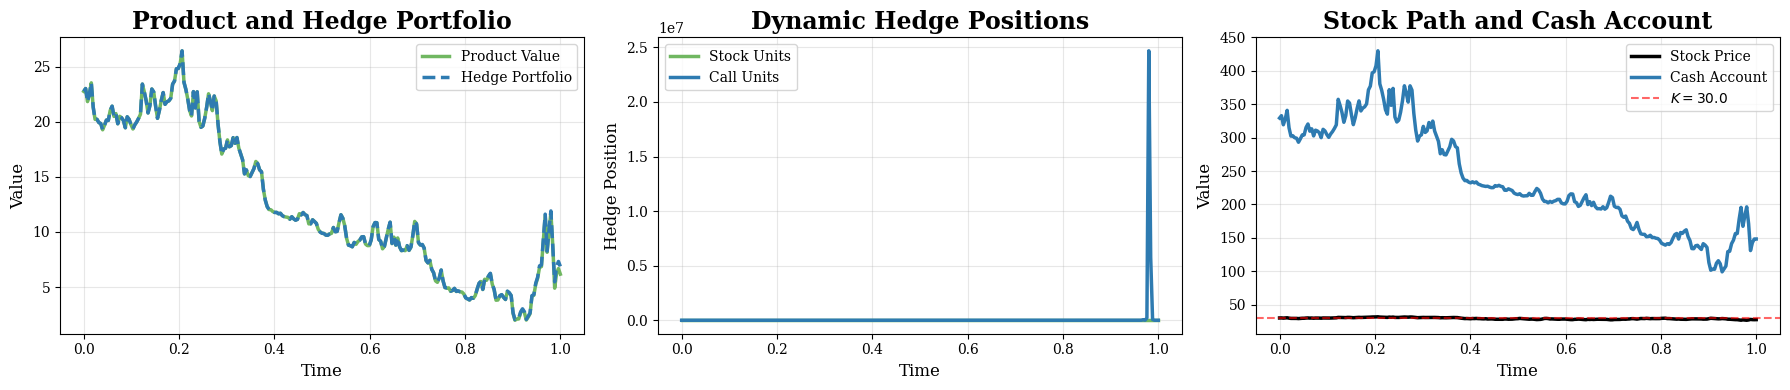

In [6]:

# =============================================================================
# 7. PLOTS
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Plot 1: Product value and hedge portfolio ---
ax = axes[0]

ax.plot(
    times,
    result["product_values"],
    color=green,
    linewidth=2.5,
    label="Product Value",
)

ax.plot(
    times,
    result["portfolio_values"],
    color=blue,
    linewidth=2.5,
    linestyle="--",
    label="Hedge Portfolio",
)

ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
ax.set_title(
    "Product and Hedge Portfolio",
    fontsize=17,
    fontweight="bold",
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)


# --- Plot 2: Stock and vanilla-call positions ---
ax = axes[1]

ax.plot(
    times,
    result["stock_units"],
    color=green,
    linewidth=2.5,
    label="Stock Units",
)

ax.plot(
    times,
    result["call_units"],
    color=blue,
    linewidth=2.5,
    label="Call Units",
)

ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Hedge Position", fontsize=12)
ax.set_title(
    "Dynamic Hedge Positions",
    fontsize=17,
    fontweight="bold",
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)


# --- Plot 3: Stock path and cash account ---
ax = axes[2]

ax.plot(
    times,
    stock_path,
    color="black",
    linewidth=2.5,
    label="Stock Price",
)

ax.plot(
    times,
    result["cash"],
    color=blue,
    linewidth=2.5,
    label="Cash Account",
)

ax.axhline(
    K,
    color="red",
    linestyle="--",
    alpha=0.6,
    label=f"$K={K}$",
)

ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
ax.set_title(
    "Stock Path and Cash Account",
    fontsize=17,
    fontweight="bold",
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()